# EDA Individual Samuel — Ketersediaan Stream dan Artifact

## Pertanyaan penelitian

**Apakah proporsi artifact_signal = 1 berbeda menurut ketersediaan signal_stream, dan bagaimana perbedaannya berubah setelah mempertimbangkan periode cycle_code serta volume narasi (text_load)?**

Analisis memakai official Classification Train TP2. Fokusnya hubungan deskriptif antara ketersediaan aliran teks dan label. Status kosong berarti teks tidak tersedia pada record, bukan bahwa isi teks berkualitas rendah.

## 1. Data dan definisi

artifact_signal = 1 menandai indikasi artefak eksploit publik yang teramati; nilai 0 bukan bukti bahwa artefak pasti tidak ada. signal_stream disebut **missing** jika null, kosong, atau hanya whitespace, mengikuti fungsi availability yang dipakai pipeline Classification. Selain itu disebut **present**.

Periode dibagi menjadi 47–57, 58–68, dan 69–79. text_load dipakai sebagai ukuran volume narasi. Analisis memakai baris Train saja; tidak ada Test atau label Test yang dibuka.

Standardisasi memakai minimum **20 observasi untuk setiap status availability dalam setiap sel**. Sel yang didukung diberi bobot yang sama bagi kedua kelompok, sebesar proporsi gabungan baris pada sel tersebut. Batas kuantil text_load dihitung dari text_load Train saja tanpa memakai availability atau target. Bin kuantil menyamakan rentang secara kasar dan tidak menjamin overlap tepat pada setiap nilai text_load.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "src" / "utils" / "paths.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari dalam repository TP2.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.eda.availability import (
    add_global_quantile_bins, prepare_availability_frame,
    prevalence_table, standardized_contrast, wilson_interval,
)
from src.models.classification_round2_models import stream_missing_mask
from src.utils.paths import task_files

train_path = task_files("classification")["train"]
if train_path is None:
    raise FileNotFoundError(
        "Letakkan official Classification Train.csv di data/raw/classification/ "
        "atau atur TP2_DATA_DIR ke folder induk data."
    )
train = pd.read_csv(train_path)
analysis = prepare_availability_frame(train, stream_missing_mask(train))
assert len(analysis) == len(train)
assert set(analysis["availability"].unique()) == {"present", "missing"}
assert analysis["cycle_code"].min() == 47 and analysis["cycle_code"].max() == 79

COLORS = {"present": "#1f4e79", "missing": "#d17a22"}
plt.rcParams.update({
    "figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
print(
    f"Sumber: official Classification Train.csv | {len(train):,} baris × {train.shape[1]} kolom | "
    f"cycle {analysis.cycle_code.min()}–{analysis.cycle_code.max()}"
)

Sumber: official Classification Train.csv | 50,608 baris × 19 kolom | cycle 47–79


## 2. Gambaran data

Tabel merangkum denominator, jumlah label positif, dan sebaran volume narasi pada setiap status availability. Angka dihitung dari Train saat notebook dijalankan.

In [2]:
grouped = prevalence_table(analysis, ["availability"]).set_index("availability").loc[["present", "missing"]]
overview = pd.DataFrame({
    "Baris (n)": grouped["n"].astype(int),
    "artifact_signal = 1 (n)": grouped["positive"].astype(int),
    "Proporsi artifact (%)": grouped["prevalence"] * 100,
    "text_load median": analysis.groupby("availability")["text_load"].median().loc[["present", "missing"]],
    "text_load Q1": analysis.groupby("availability")["text_load"].quantile(.25).loc[["present", "missing"]],
    "text_load Q3": analysis.groupby("availability")["text_load"].quantile(.75).loc[["present", "missing"]],
})
overview.index.name = "Availability"
display(overview.round(2))
print(
    f"Total Train {len(analysis):,}; label positif {analysis.artifact_signal.sum():,} "
    f"({analysis.artifact_signal.mean():.2%}); cycle unik {analysis.cycle_code.nunique()}."
)

,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


## 3. Perbandingan marginal

Perbandingan awal memakai seluruh baris pada setiap kelompok. Interval Wilson 95% menjelaskan ketidakpastian tiap proporsi marginal secara terpisah; interval ini bukan interval untuk selisih kedua kelompok.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

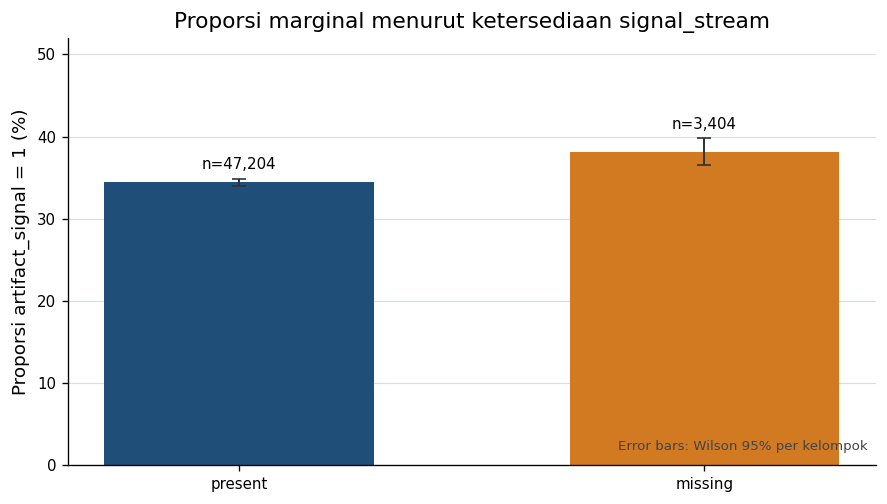

In [3]:
marginal_rows = []
for availability in ("present", "missing"):
    part = analysis.loc[analysis.availability.eq(availability)]
    successes, n = int(part.artifact_signal.sum()), int(len(part))
    low, high = wilson_interval(successes, n)
    marginal_rows.append({
        "Ketersediaan": availability, "artifact_signal = 1 (n)": successes,
        "Denominator (n)": n, "Proporsi (%)": 100 * successes / n,
        "Wilson 95% bawah (%)": 100 * low, "Wilson 95% atas (%)": 100 * high,
    })
marginal = pd.DataFrame(marginal_rows)
marginal_indexed = marginal.set_index("Ketersediaan")
marginal_gap_pp = marginal_indexed.loc["missing", "Proporsi (%)"] - marginal_indexed.loc["present", "Proporsi (%)"]
display(marginal.round(2))
display(Markdown(
    f"Proporsi artifact pada Train adalah **{marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** "
    f"saat stream tersedia dan **{marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. "
    f"Selisih missing − present adalah **{marginal_gap_pp:+.2f} poin persentase (pp)**."
))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
x = np.arange(len(marginal))
rates = marginal["Proporsi (%)"].to_numpy()
lower = rates - marginal["Wilson 95% bawah (%)"].to_numpy()
upper = marginal["Wilson 95% atas (%)"].to_numpy() - rates
ax.bar(x, rates, color=[COLORS[name] for name in marginal["Ketersediaan"]], width=.58, zorder=2)
ax.errorbar(x, rates, yerr=np.vstack([lower, upper]), fmt="none", ecolor="#30343b", capsize=4, lw=1.2, zorder=3)
for i, row in marginal.iterrows():
    ax.text(i, row["Wilson 95% atas (%)"] + 1.2, f"n={int(row['Denominator (n)']):,}", ha="center", fontsize=9)
ax.set_xticks(x, marginal["Ketersediaan"])
ax.set_ylabel("Proporsi artifact_signal = 1 (%)")
ax.set_title("Proporsi marginal menurut ketersediaan signal_stream")
ax.set_ylim(0, 52)
ax.grid(axis="y", color="#d9dde3", linewidth=.7, zorder=0)
ax.text(.99, .03, "Error bars: Wilson 95% per kelompok", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="#40444b")
fig.tight_layout()
plt.show()

## 4. Perbedaan menurut periode dan cycle

Prevalence dapat berubah sepanjang waktu. Grafik kiri memperlihatkan selisih per cycle (missing − present); grafik kanan membandingkan proporsi dan denominator pada tiga periode. Selisih positif tidak berlaku pada semua periode atau cycle.

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


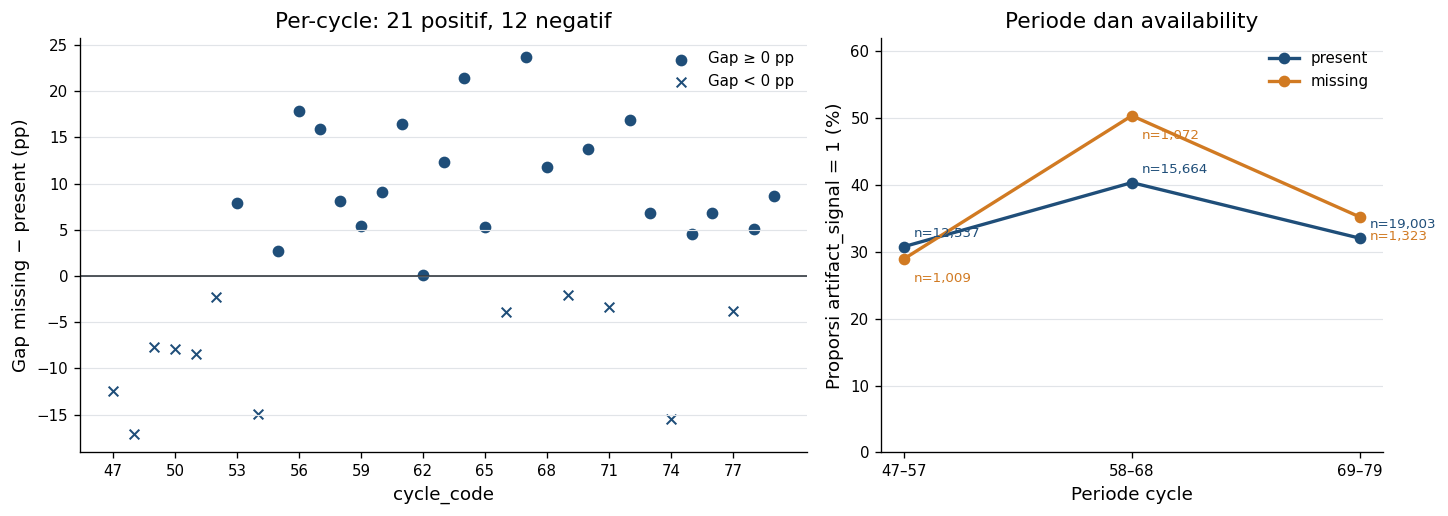

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [4]:
period_prevalence = prevalence_table(analysis, ["period", "availability"])
period_pivot = period_prevalence.pivot(index="period", columns="availability", values="prevalence").loc[["47–57", "58–68", "69–79"]]
period_n = period_prevalence.pivot(index="period", columns="availability", values="n").loc[period_pivot.index]
period_summary = pd.DataFrame({
    "Present n": period_n["present"].astype(int),
    "Present (%)": 100 * period_pivot["present"],
    "Missing n": period_n["missing"].astype(int),
    "Missing (%)": 100 * period_pivot["missing"],
    "Gap missing − present (pp)": 100 * (period_pivot["missing"] - period_pivot["present"]),
})
display(period_summary.round(2))

cycle_prevalence = prevalence_table(analysis, ["cycle_code", "availability"])
cycle_rates = cycle_prevalence.pivot(index="cycle_code", columns="availability", values="prevalence")
cycle_n = cycle_prevalence.pivot(index="cycle_code", columns="availability", values="n")
cycle_gap = 100 * (cycle_rates["missing"] - cycle_rates["present"])
cycle_supported = cycle_n["missing"].ge(20) & cycle_n["present"].ge(20)
assert cycle_supported.all(), "Exact-cycle graph must not include unsupported groups"
positive_cycles = int((cycle_gap > 0).sum())
negative_cycles = int((cycle_gap < 0).sum())

fig, (ax_cycle, ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={"width_ratios": [1.45, 1]})
for marker, condition, label in [
    ("o", cycle_gap >= 0, "Gap ≥ 0 pp"),
    ("x", cycle_gap < 0, "Gap < 0 pp"),
]:
    ax_cycle.scatter(cycle_gap.index[condition], cycle_gap.loc[condition], marker=marker, s=34,
                     color=COLORS["present"], label=label, linewidths=1.2)
ax_cycle.axhline(0, color="#343a40", lw=1)
ax_cycle.set_xticks(np.arange(47, 80, 3))
ax_cycle.set_xlabel("cycle_code")
ax_cycle.set_ylabel("Gap missing − present (pp)")
ax_cycle.set_title(f"Per-cycle: {positive_cycles} positif, {negative_cycles} negatif")
ax_cycle.legend(frameon=False, loc="best")
ax_cycle.grid(axis="y", color="#e1e4e8", linewidth=.7)

period_x = np.arange(len(period_pivot))
for availability in ("present", "missing"):
    values = 100 * period_pivot[availability].to_numpy()
    ax_period.plot(period_x, values, marker="o", lw=2, color=COLORS[availability], label=availability)
    for j, (value, n) in enumerate(zip(values, period_n[availability].to_numpy())):
        offset = (6, 6) if availability == "present" else (6, -14)
        ax_period.annotate(f"n={int(n):,}", (j, value), xytext=offset, textcoords="offset points",
                           fontsize=8, color=COLORS[availability])
ax_period.set_xticks(period_x, period_pivot.index)
ax_period.set_xlabel("Periode cycle")
ax_period.set_ylabel("Proporsi artifact_signal = 1 (%)")
ax_period.set_title("Periode dan availability")
ax_period.set_ylim(0, 62)
ax_period.legend(frameon=False)
ax_period.grid(axis="y", color="#e1e4e8", linewidth=.7)
fig.tight_layout()
plt.show()

display(Markdown(
    f"Gap per periode ialah **{period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, "
    f"**{period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan "
    f"**{period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. "
    f"Pada cycle dengan n≥20 untuk masing-masing status, {positive_cycles}/{len(cycle_gap)} gap positif "
    f"dan {negative_cycles}/{len(cycle_gap)} negatif; rentangnya {cycle_gap.min():+.2f} sampai {cycle_gap.max():+.2f} pp."
))

## 5. Volume narasi (text_load)

text_load berbeda menurut availability, sehingga perbandingan marginal dapat mencampur kelompok dengan komposisi volume berbeda. Histogram memakai density agar skala tidak didominasi kelompok present yang memiliki denominator jauh lebih besar.

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


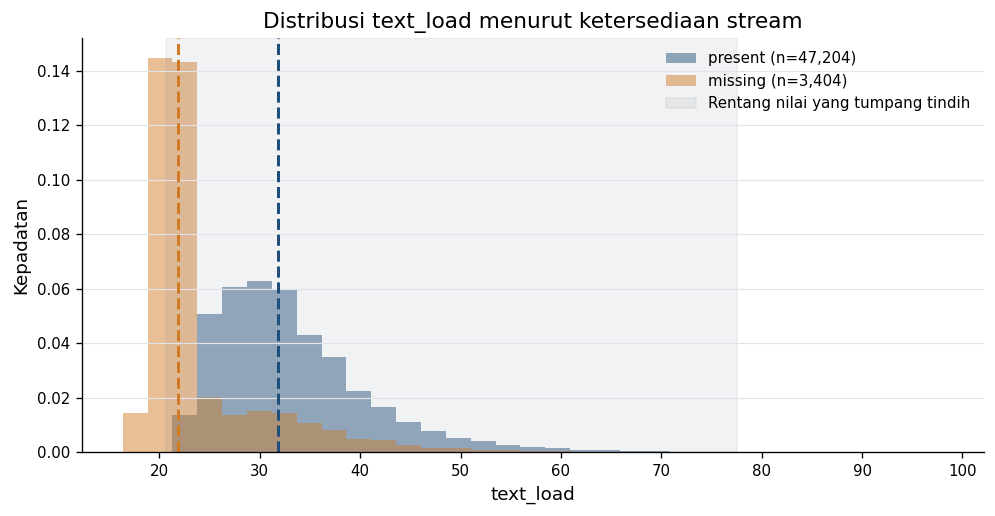

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [5]:
text_summary = analysis.groupby("availability")["text_load"].agg(
    n="size", minimum="min", q1=lambda x: x.quantile(.25), median="median",
    q3=lambda x: x.quantile(.75), maximum="max"
).loc[["present", "missing"]]
overlap_low = max(text_summary.loc["present", "minimum"], text_summary.loc["missing", "minimum"])
overlap_high = min(text_summary.loc["present", "maximum"], text_summary.loc["missing", "maximum"])
outside_missing = int((analysis.availability.eq("missing") & ~analysis.text_load.between(overlap_low, overlap_high)).sum())
outside_present = int((analysis.availability.eq("present") & ~analysis.text_load.between(overlap_low, overlap_high)).sum())
display(text_summary.round(2))

fig, ax = plt.subplots(figsize=(8.4, 4.4))
bins = np.linspace(analysis.text_load.min(), analysis.text_load.max(), 34)
for availability in ("present", "missing"):
    values = analysis.loc[analysis.availability.eq(availability), "text_load"]
    ax.hist(values, bins=bins, density=True, alpha=.48, color=COLORS[availability],
            label=f"{availability} (n={len(values):,})")
    ax.axvline(values.median(), color=COLORS[availability], lw=1.8, linestyle="--")
ax.axvspan(overlap_low, overlap_high, color="#78828f", alpha=.10, label="Rentang nilai yang tumpang tindih")
ax.set_xlabel("text_load")
ax.set_ylabel("Kepadatan")
ax.set_title("Distribusi text_load menurut ketersediaan stream")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e1e4e8", linewidth=.7)
fig.tight_layout()
plt.show()

display(Markdown(
    f"Median text_load adalah **{text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan "
    f"**{text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati "
    f"adalah **{overlap_low:.2f}–{overlap_high:.2f}**; di luarnya terdapat {outside_missing:,} baris missing "
    f"dan {outside_present:,} baris present."
))

## 6. Standardisasi terhadap cycle dan volume

Kontras menyamakan bobot komposisi cell agar kedua status availability dibandingkan pada komposisi cycle/volume yang sama. Standardisasi exact cycle masih mencakup semua baris karena setiap cycle memiliki ≥20 baris dari tiap status. Analisis gabungan memakai periode × kuantil global text_load 5 dan 10 bins.

In [6]:
cycle_standardized, cycle_cells = standardized_contrast(analysis, ["cycle_code"], min_support=20)
q5_frame, q5_edges = add_global_quantile_bins(analysis, 5)
period_q5, period_q5_cells = standardized_contrast(q5_frame, ["period", "text_load_q5"], min_support=20)
q10_frame, q10_edges = add_global_quantile_bins(analysis, 10)
period_q10, period_q10_cells = standardized_contrast(q10_frame, ["period", "text_load_q10"], min_support=20)

comparison_rows = [{
    "Kontras": "Marginal (seluruh Train)",
    "Present (%)": marginal_indexed.loc["present", "Proporsi (%)"],
    "Missing (%)": marginal_indexed.loc["missing", "Proporsi (%)"],
    "Gap missing − present (pp)": marginal_gap_pp,
    "Sel didukung": "—",
    "Baris present tercakup": int(analysis.availability.eq("present").sum()),
    "Baris missing tercakup": int(analysis.availability.eq("missing").sum()),
    "Coverage keseluruhan (%)": 100.0,
}]
for label, result in [
    ("Exact cycle", cycle_standardized),
    ("Periode × kuantil text_load (5)", period_q5),
    ("Periode × kuantil text_load (10)", period_q10),
]:
    comparison_rows.append({
        "Kontras": label,
        "Present (%)": 100 * result["standardized_prevalence"]["present"],
        "Missing (%)": 100 * result["standardized_prevalence"]["missing"],
        "Gap missing − present (pp)": result["standardized_missing_minus_present_pp"],
        "Sel didukung": f"{result['cells_supported']}/{result['cells_total']}",
        "Baris present tercakup": result["covered_rows_by_availability"]["present"],
        "Baris missing tercakup": result["covered_rows_by_availability"]["missing"],
        "Coverage keseluruhan (%)": 100 * result["coverage_all_rows"],
    })
contrasts = pd.DataFrame(comparison_rows)
display(contrasts.round(2))

support_by_group = pd.DataFrame([
    {"Kontras": "Exact cycle",
     "Coverage present (%)": 100 * cycle_standardized["coverage_by_availability"]["present"],
     "Coverage missing (%)": 100 * cycle_standardized["coverage_by_availability"]["missing"]},
    {"Kontras": "Periode × kuantil 5",
     "Coverage present (%)": 100 * period_q5["coverage_by_availability"]["present"],
     "Coverage missing (%)": 100 * period_q5["coverage_by_availability"]["missing"]},
    {"Kontras": "Periode × kuantil 10",
     "Coverage present (%)": 100 * period_q10["coverage_by_availability"]["present"],
     "Coverage missing (%)": 100 * period_q10["coverage_by_availability"]["missing"]},
])
display(support_by_group.round(2))
print(f"Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(q5_edges)-1}; 10-bin={len(q10_edges)-1}.")

,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


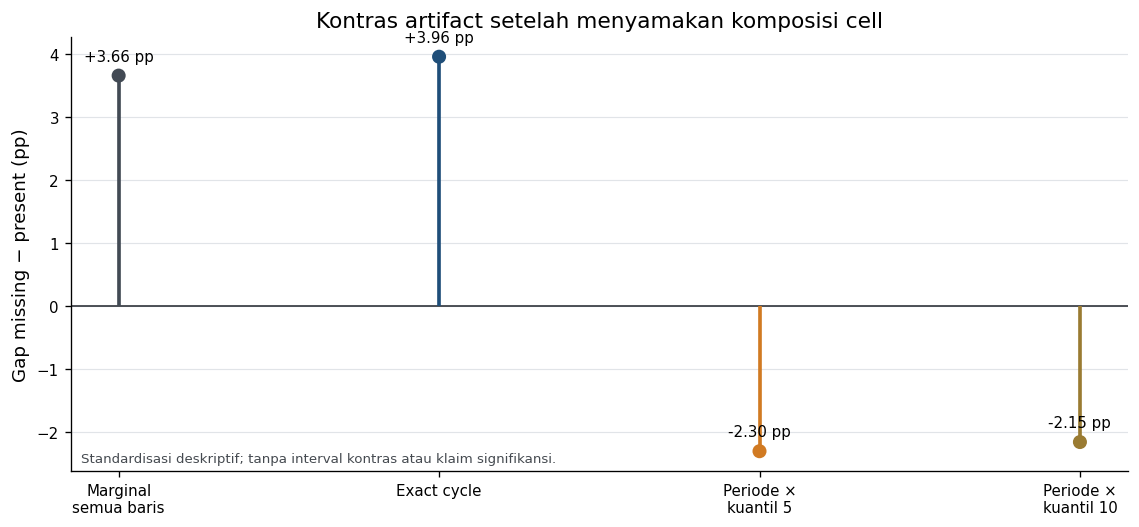

In [7]:
fig, ax = plt.subplots(figsize=(9.6, 4.5))
labels = ["Marginal\nsemua baris", "Exact cycle", "Periode ×\nkuantil 5", "Periode ×\nkuantil 10"]
gaps = contrasts["Gap missing − present (pp)"].to_numpy()
colors = ["#424a54", "#1f4e79", "#d17a22", "#9a7b32"]
x = np.arange(len(gaps))
ax.axhline(0, color="#30343b", lw=1)
ax.vlines(x, 0, gaps, color=colors, lw=2.2)
ax.scatter(x, gaps, color=colors, s=55, zorder=3)
for i, row in contrasts.iterrows():
    value = row["Gap missing − present (pp)"]
    ax.annotate(f"{value:+.2f} pp", (i, value),
                xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylabel("Gap missing − present (pp)")
ax.set_title("Kontras artifact setelah menyamakan komposisi cell")
ax.grid(axis="y", color="#e1e4e8", linewidth=.7)
ax.text(.01, .02, "Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.",
        transform=ax.transAxes, fontsize=8, color="#454a50")
fig.tight_layout()
plt.show()

## 7. Interpretasi dan keterbatasan

Arah positif berarti proporsi pada kelompok missing lebih tinggi daripada kelompok present. Standardisasi menyamakan komposisi hanya pada strata yang ditentukan.

In [8]:
q10_unsupported = period_q10_cells.loc[~period_q10_cells.supported]
display(Markdown(
    f"**Interpretasi utama.** Secara marginal, proporsi label positif pada stream missing lebih tinggi "
    f"{marginal_gap_pp:+.2f} pp. Setelah menyamakan distribusi exact cycle, gap menjadi "
    f"{cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp dengan coverage "
    f"{cycle_standardized['coverage_all_rows']:.2%}. Setelah menyamakan periode dan kuantil volume, gap "
    f"menjadi {period_q5['standardized_missing_minus_present_pp']:+.2f} pp untuk 5 bin dan "
    f"{period_q10['standardized_missing_minus_present_pp']:+.2f} pp untuk 10 bin "
    f"(coverage 10-bin {period_q10['coverage_all_rows']:.2%}; {period_q10['cells_supported']}/"
    f"{period_q10['cells_total']} sel didukung). Arah asosiasi deskriptif sensitif pada komposisi waktu "
    f"dan volume; ini bukan bukti bahwa missingness atau volume menyebabkan label."
))
display(Markdown(
    f"**Support.** Minimum per sel adalah n≥20 untuk present dan missing. Exact cycle mencakup "
    f"{cycle_standardized['supported_rows_total']:,}/{len(analysis):,} baris; periode×5 mencakup "
    f"{period_q5['supported_rows_total']:,}/{len(analysis):,}; periode×10 mencakup "
    f"{period_q10['supported_rows_total']:,}/{len(analysis):,}. Ada {len(q10_unsupported)} sel 10-bin "
    f"yang tidak didukung. Denominator 10-bin yang tercakup adalah "
    f"{period_q10['covered_rows_by_availability']['missing']:,}/"
    f"{period_q10['total_rows_by_availability']['missing']:,} missing dan "
    f"{period_q10['covered_rows_by_availability']['present']:,}/"
    f"{period_q10['total_rows_by_availability']['present']:,} present."
))
display(Markdown(
    f"Rentang text_load yang sama-sama teramati adalah {overlap_low:.2f}–{overlap_high:.2f}; ada "
    f"{outside_missing:,} baris missing dan {outside_present:,} present di luar rentang itu. Karena "
    f"standardisasi memakai bins kasar, dukungan dalam suatu bin tidak berarti setiap nilai text_load "
    f"memiliki pasangan pembanding tepat."
))
display(Markdown(
    "**Batas interpretasi.** Hasil ini adalah asosiasi pada Train; ia tidak mengidentifikasi proses "
    "pengumpulan, makna teks anonim, kualitas teks, atau sebab-akibat. Ia tidak menghilangkan seluruh "
    "confounding, tidak menjamin pola serupa pada official Test, dan tidak menguji selisih dengan inferensi "
    "statistik. Stream kosong tidak menyumbang isi teks. Semua cycle Train telah dipakai dalam pengembangan "
    "eksperimen sehingga hasil ini bukan konfirmasi independen."
))
display(Markdown(
    "**Kaitan dengan Classification.** Diagnosis model terdahulu secara terpisah menemukan hybrid C2_B "
    "lebih lemah pada stream missing (Macro F1 0.710427), sedangkan structured HGB C1_B mencapai 0.781712; "
    "C4_HGB kemudian memakai routing availability. EDA raw ini dibuat setelah diagnosis model, jadi ia "
    "memberi konteks komposisi availability, bukan penyebab atau bukti tunggal bahwa routing meningkatkan skor."
))

**Interpretasi utama.** Secara marginal, proporsi label positif pada stream missing lebih tinggi +3.66 pp. Setelah menyamakan distribusi exact cycle, gap menjadi +3.96 pp dengan coverage 100.00%. Setelah menyamakan periode dan kuantil volume, gap menjadi -2.30 pp untuk 5 bin dan -2.15 pp untuk 10 bin (coverage 10-bin 94.33%; 28/30 sel didukung). Arah asosiasi deskriptif sensitif pada komposisi waktu dan volume; ini bukan bukti bahwa missingness atau volume menyebabkan label.

**Support.** Minimum per sel adalah n≥20 untuk present dan missing. Exact cycle mencakup 50,608/50,608 baris; periode×5 mencakup 50,608/50,608; periode×10 mencakup 47,740/50,608. Ada 2 sel 10-bin yang tidak didukung. Denominator 10-bin yang tercakup adalah 3,372/3,404 missing dan 44,368/47,204 present.

Rentang text_load yang sama-sama teramati adalah 20.65–77.52; ada 906 baris missing dan 65 present di luar rentang itu. Karena standardisasi memakai bins kasar, dukungan dalam suatu bin tidak berarti setiap nilai text_load memiliki pasangan pembanding tepat.

**Batas interpretasi.** Hasil ini adalah asosiasi pada Train; ia tidak mengidentifikasi proses pengumpulan, makna teks anonim, kualitas teks, atau sebab-akibat. Ia tidak menghilangkan seluruh confounding, tidak menjamin pola serupa pada official Test, dan tidak menguji selisih dengan inferensi statistik. Stream kosong tidak menyumbang isi teks. Semua cycle Train telah dipakai dalam pengembangan eksperimen sehingga hasil ini bukan konfirmasi independen.

**Kaitan dengan Classification.** Diagnosis model terdahulu secara terpisah menemukan hybrid C2_B lebih lemah pada stream missing (Macro F1 0.710427), sedangkan structured HGB C1_B mencapai 0.781712; C4_HGB kemudian memakai routing availability. EDA raw ini dibuat setelah diagnosis model, jadi ia memberi konteks komposisi availability, bukan penyebab atau bukti tunggal bahwa routing meningkatkan skor.

## 8. Kesimpulan

Pada official Classification Train, proporsi artifact_signal = 1 berbeda menurut ketersediaan signal_stream. Selisih marginal missing − present positif **+3,66 pp** dan tetap **+3,96 pp** setelah standardisasi exact cycle dengan seluruh baris didukung. Setelah menyamakan periode bersama kuantil text_load, selisih menjadi negatif (sekitar **−2,2 sampai −2,3 pp**); estimasi ini memakai bin kasar, dan standardisasi 10-bin mencakup **94,33%** baris. Perubahan tersebut menunjukkan sensitivitas komposisi periode dan volume, bukan efek kausal. Hubungan bervariasi antarperiode/cycle dan common support tidak sempurna.